In [1]:
import pandas as pd
import numpy as np
import sklearn # scikit-learn kutubxonasi
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
URL = "https://github.com/ageron/handson-ml2/blob/master/datasets/housing/housing.csv?raw=true"
df = pd.read_csv(URL)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [5]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


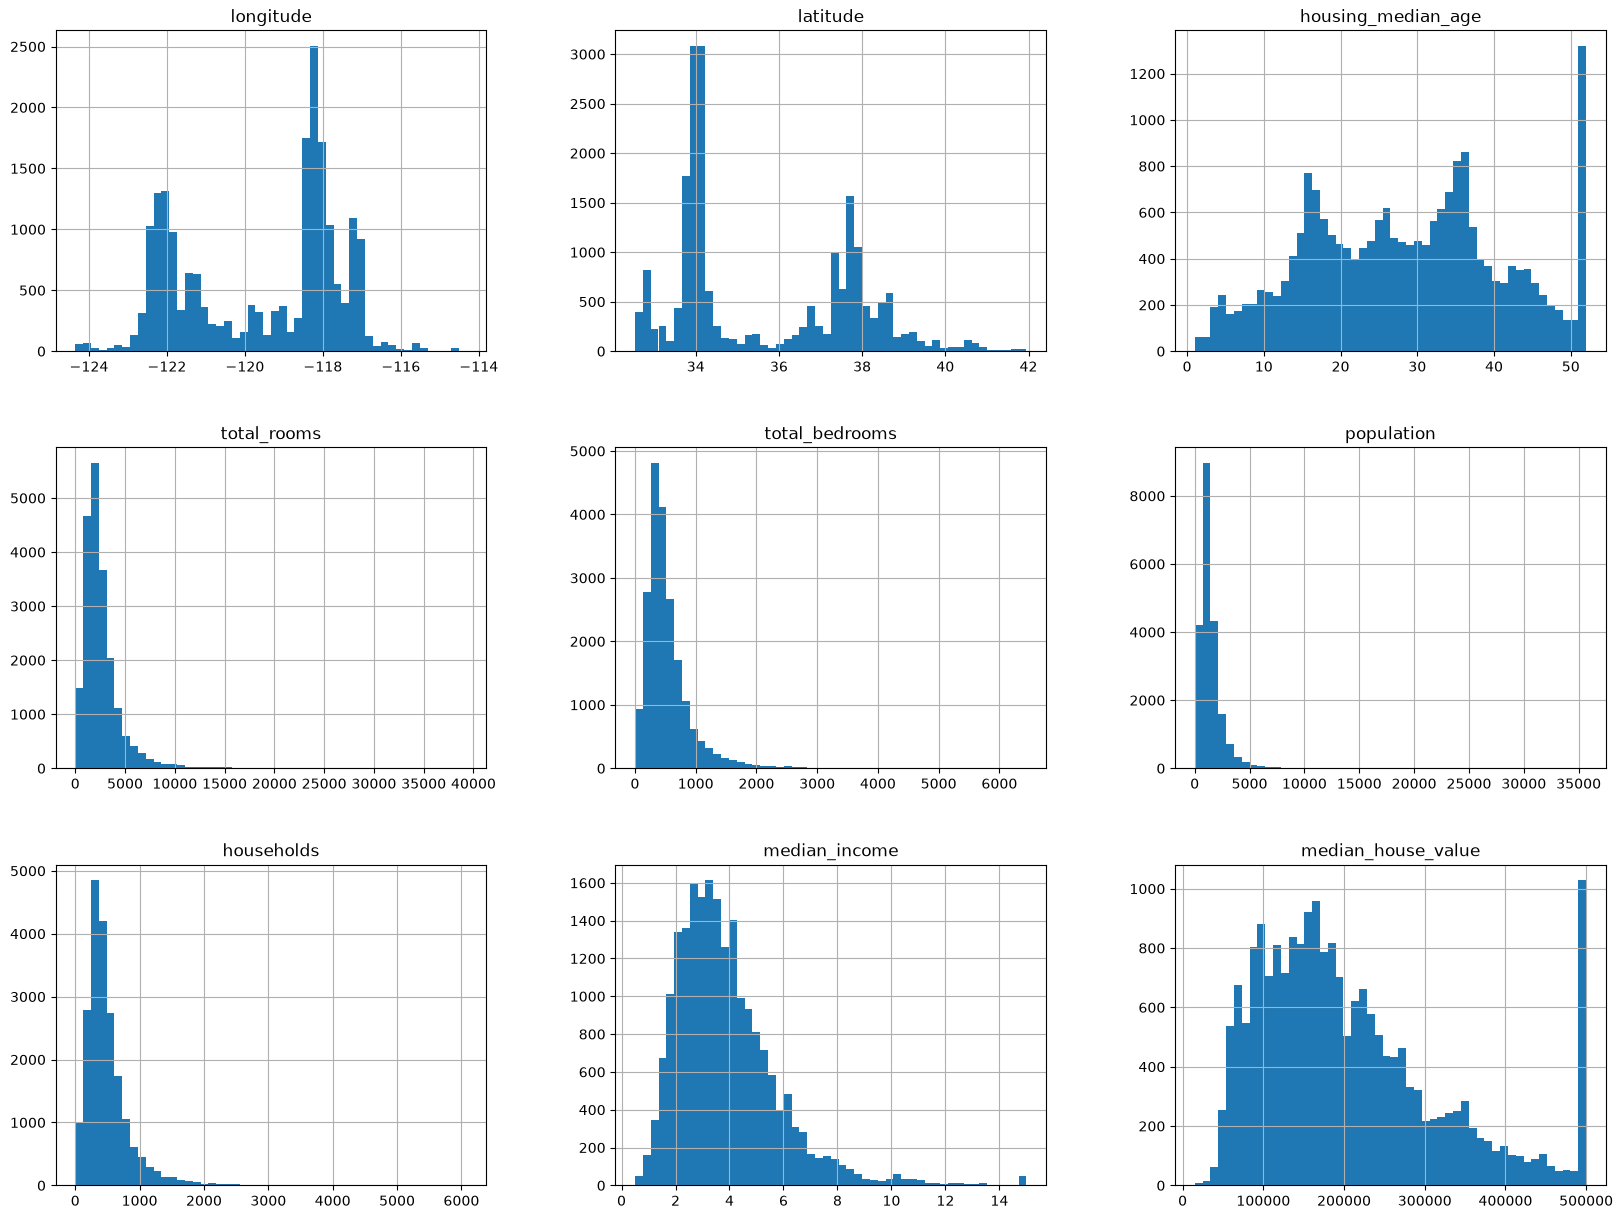

In [6]:
%matplotlib inline
df.hist(bins=50, figsize=(20,15))
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

In [9]:
train_set.shape

(16512, 10)

In [10]:
test_set.shape

(4128, 10)

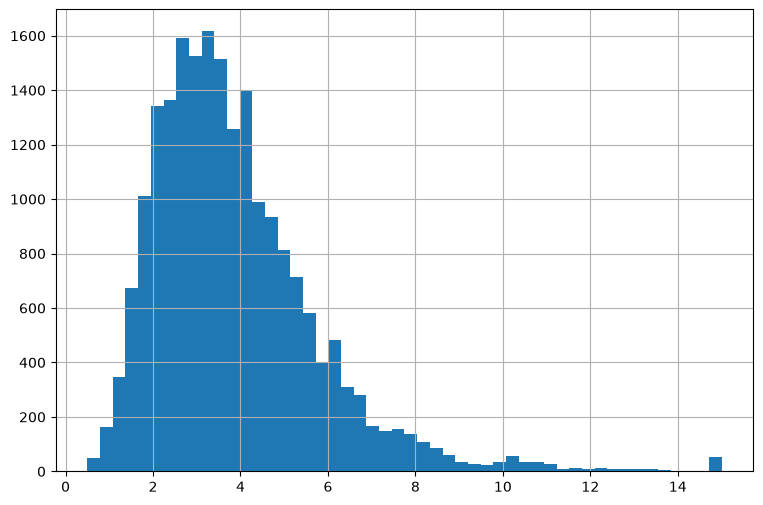

In [11]:
%matplotlib inline
df['median_income'].hist(bins=50, figsize=(9,6))
plt.show()

StratifiedShuffleSplitdan foydalanishdan avval median_income ustunidagi qiymatlarni bir nechta kategoriyalarga ajratib olishimiz kerak. Aynan shu kategoriyalar StratifiedShuffleSplit ichidagi split funksiyasiga uzatiladi va funksiya shu kategoriya asosida train va test set o'rtasidagi balansni saqlaydi.

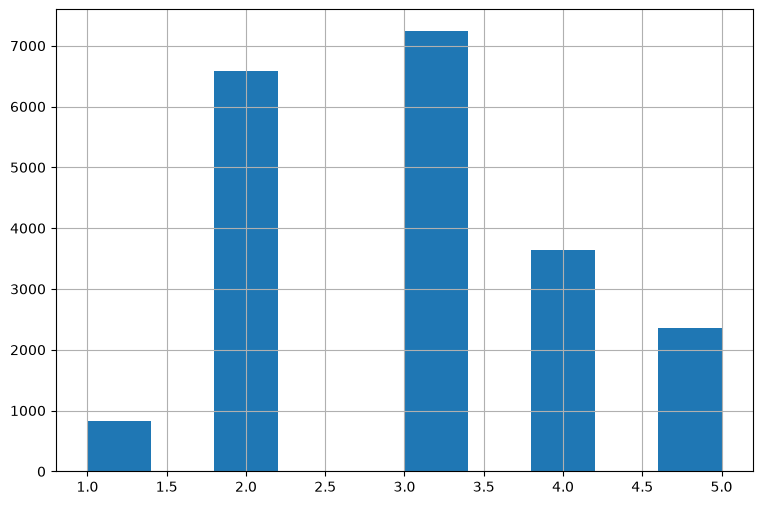

In [12]:
df['income_cat'] = pd.cut(df['median_income'], bins=[0., 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1,2,3,4,5])
df['income_cat'].hist(figsize=(9,6))
plt.show()

In [14]:
from sklearn.model_selection import StratifiedShuffleSplit
stratified_split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in stratified_split.split(df, df['income_cat']):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

In [17]:
strat_train_set.drop('income_cat', axis=1, inplace=True)
strat_test_set.drop('income_cat', axis=1, inplace=True)

KeyError: "['income_cat'] not found in axis"

### Ma'lumotlarni tahlil qilamiz.

In [18]:
housing = strat_train_set.copy()

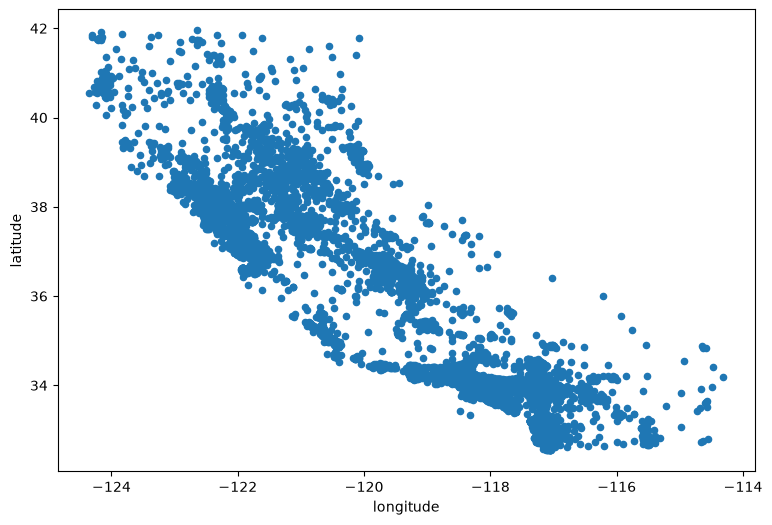

In [19]:
housing.plot(kind='scatter', x='longitude', y='latitude', figsize=(9,6))
plt.show()

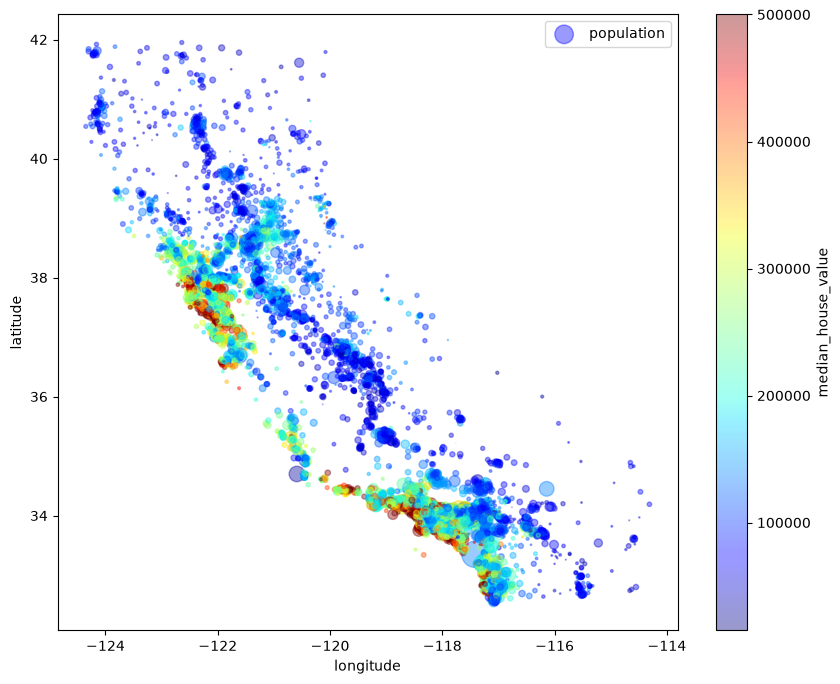

In [21]:
housing.plot(
    kind='scatter',
    x='longitude',
    y='latitude',
    alpha=0.4, 
    s=housing['population']/100,
    label='population',
    c='median_house_value',
    cmap='jet',
    colorbar=True,
    figsize=(10,8)
)
plt.show()

### Korrelyasiya

In [24]:
housing.corrwith(housing['median_house_value'], numeric_only=True).sort_values(ascending=False)

median_house_value    1.000000
median_income         0.687151
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
dtype: float64

`seabron` tarkibidagi `pairplot` funksiyasi yordamida korrelyasiya qiymatlarini grafik ko'rinishida chiqarishimiz ham mumkin.

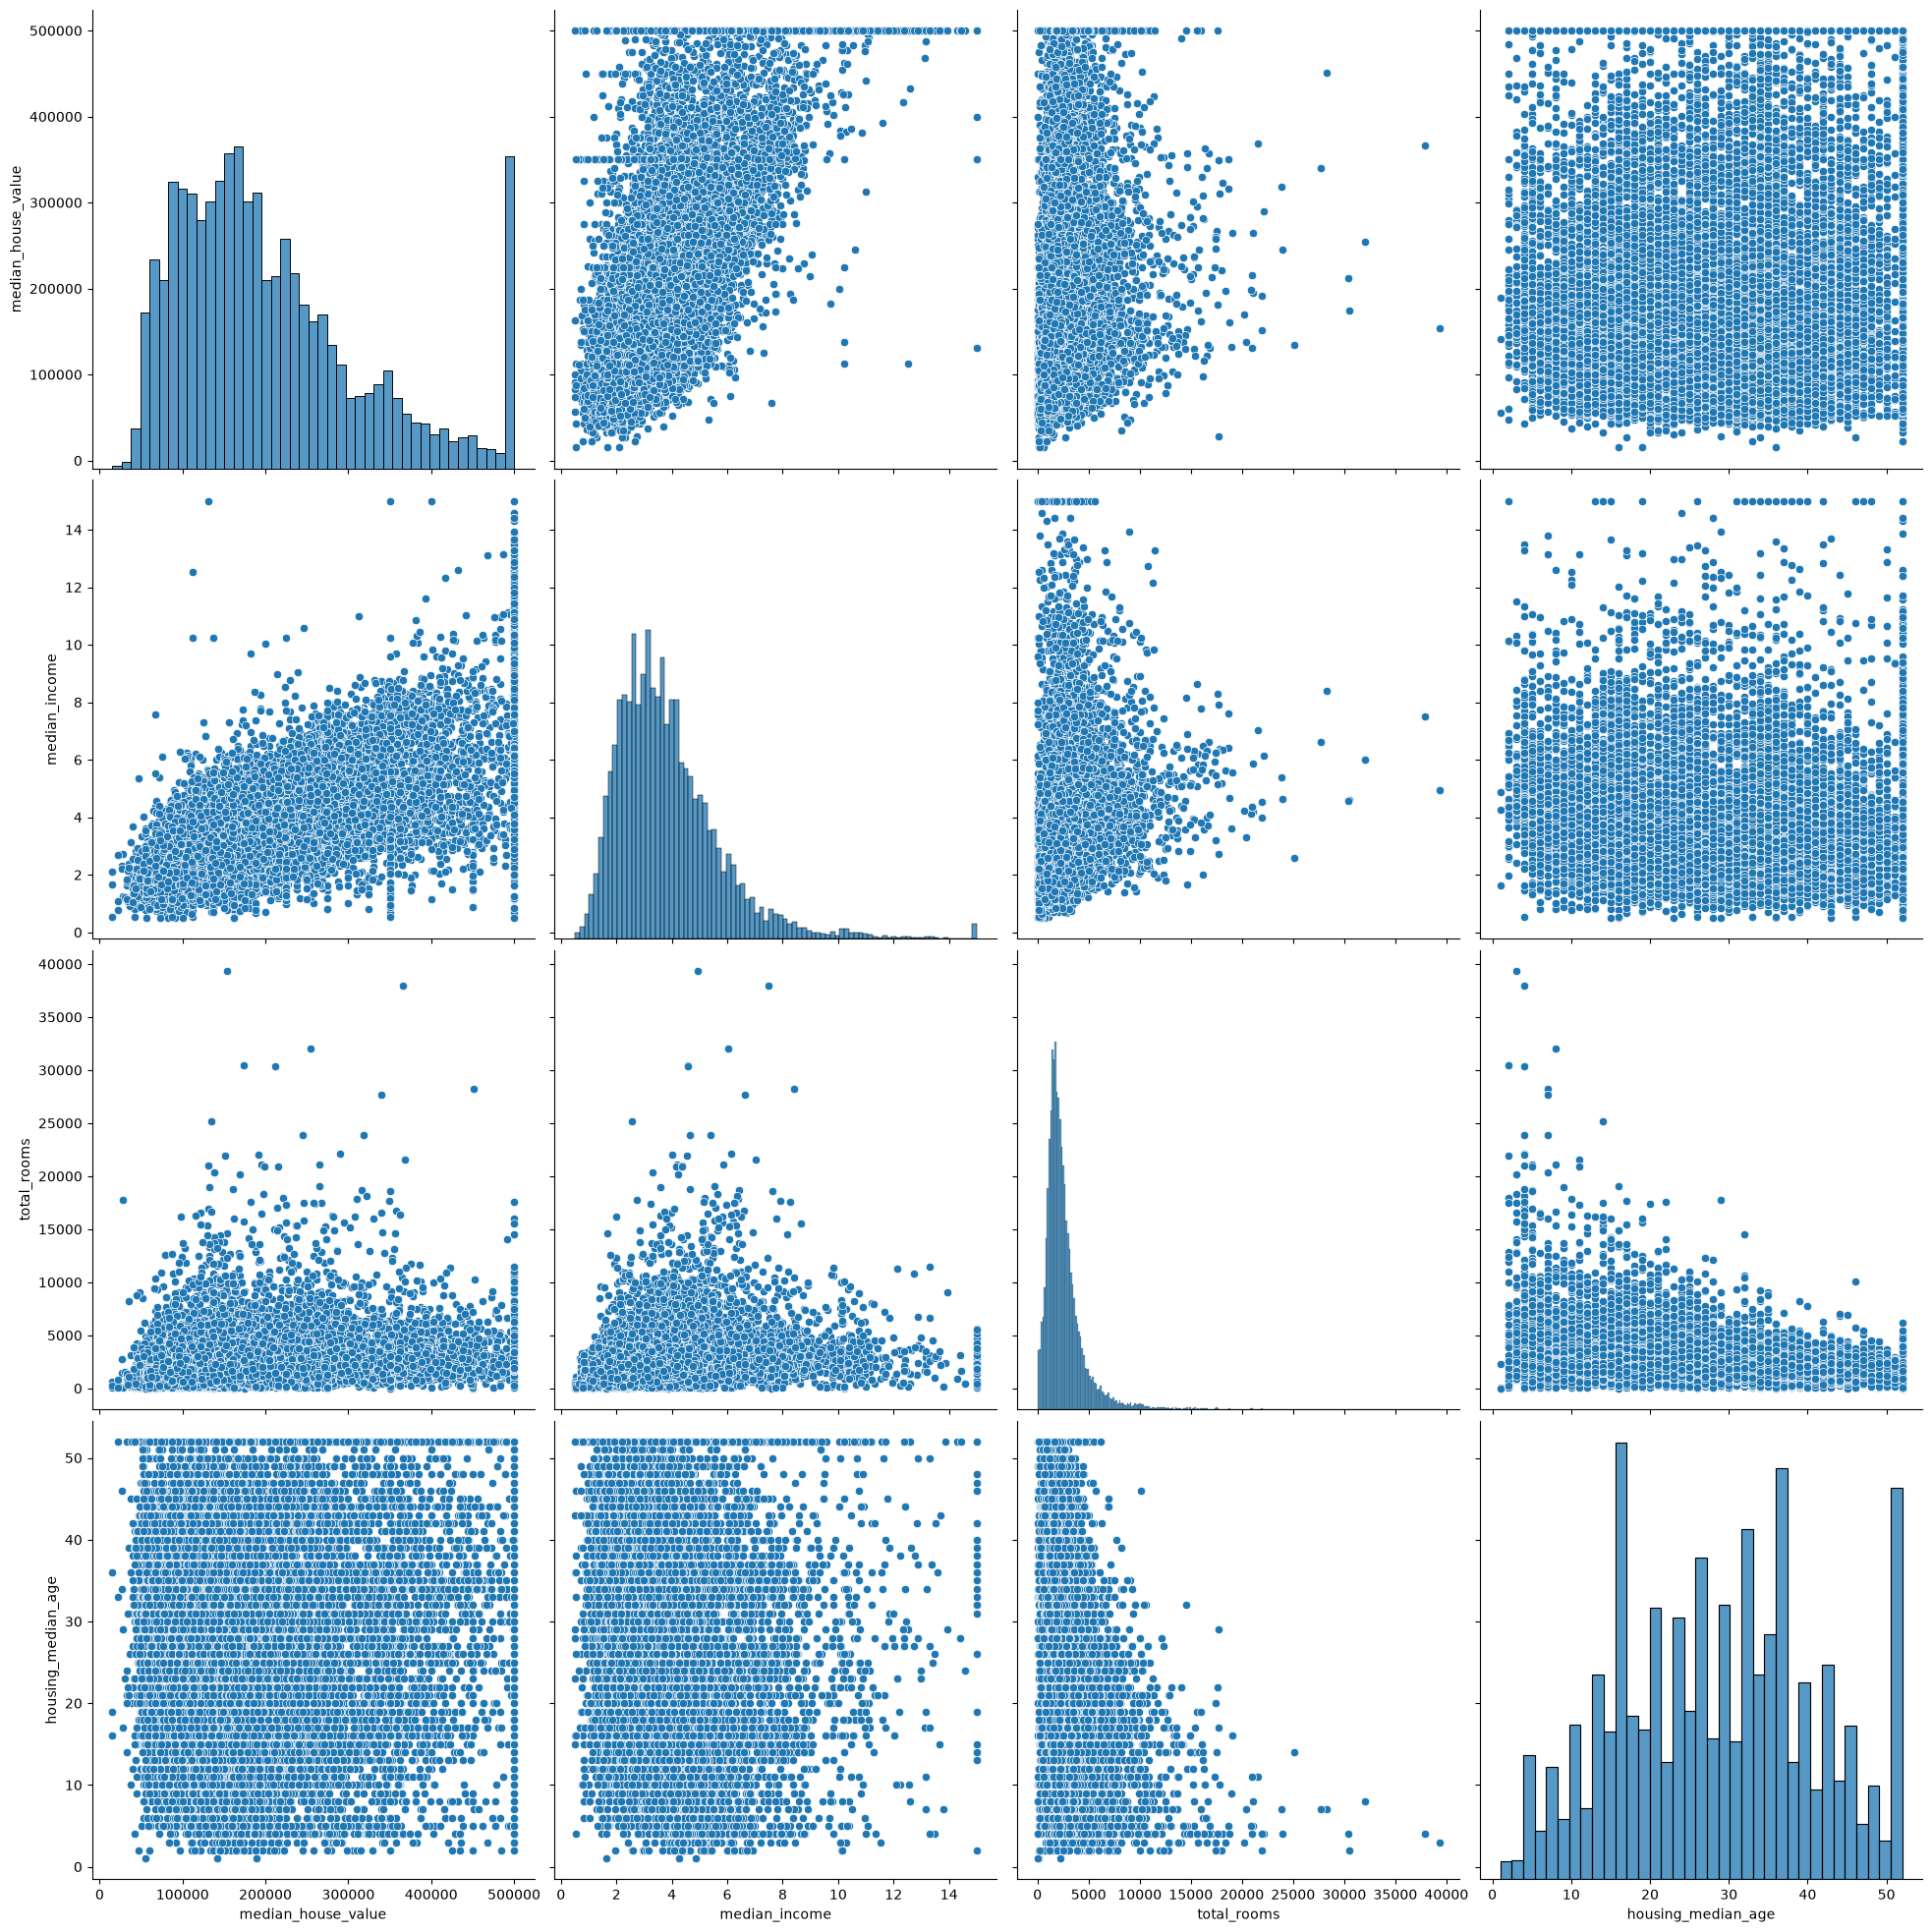

In [25]:
cols = ['median_house_value','median_income','total_rooms','housing_median_age']
sns.pairplot(housing[cols], height=5)
plt.show()

#### Barcha ustunlar orasida `median_income` va uy narxi o'rtasida korrelyatsiya eng kuchli ekan, keling uni alohida chizaylik.

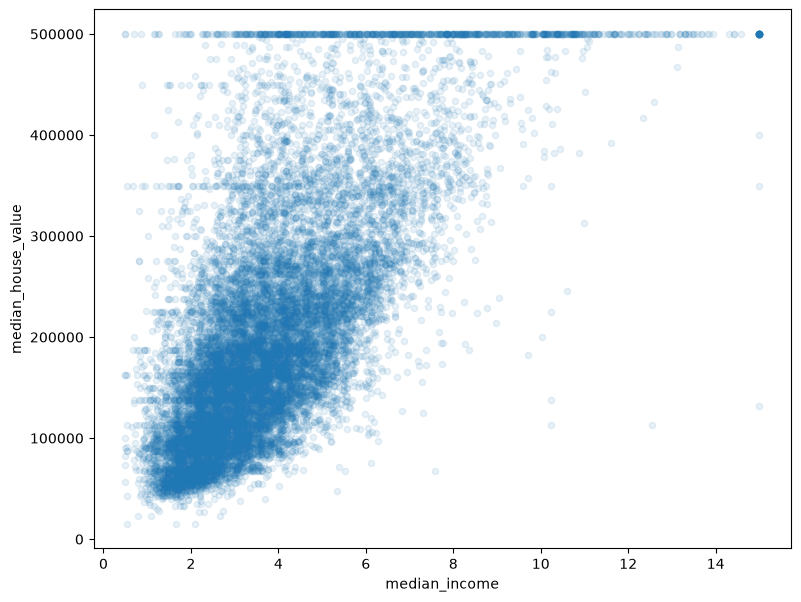

In [27]:
housing.plot(kind='scatter', x='median_income', y='median_house_value', alpha=0.1, figsize=(9,7))
plt.show()

#### Yangi parametrlar yaratamiz
Yuqorida median_income uylarning median bahosini topish uchun yaxshi parametr ekanini ko'rdik, lekin bu parametrning o'zi yetarli emas. Shunday holatlarda ba'zi parametrlani jamlab yangi parametrlar hosil qilishimiz mumkin.

Misol uchun, hududdagi jami xonalar soni (total_rooms) unchalik ham muhim emas, lekin jami xonalar sonini jami xonadonlar (households) soniga bo'lsak har bir xonadon uchun o'rtacha xonalar soni chiqadi (ya'ni har bir uyning o'rtacha xonalari soni) bu esa uyning bahosini aniqlashda muhim bo'lishi mumkin.

In [28]:
housing['rooms_per_household'] = housing['total_rooms']/housing['households']
housing['bedrooms_per_room'] = housing['total_bedrooms']/housing['total_rooms']
housing['population_per_household'] = housing['population']/housing['households']

In [30]:
housing.corrwith(housing['median_house_value'], numeric_only=True).sort_values(ascending=False)


median_house_value          1.000000
median_income               0.687151
rooms_per_household         0.146255
total_rooms                 0.135140
housing_median_age          0.114146
households                  0.064590
total_bedrooms              0.047781
population_per_household   -0.021991
population                 -0.026882
longitude                  -0.047466
latitude                   -0.142673
bedrooms_per_room          -0.259952
dtype: float64

In [1]:
import os
print(os.getcwd())

C:\Users\User\anaconda_projects\b43b02b3-424b-4011-a1ff-fcf33d407029
